<a href="https://colab.research.google.com/github/SamShinwari/tensorflow-from-scratch/blob/main/TensorFlow_%E2%80%94_Day_2%2C_Part_1_Your_First_Keras_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TensorFlow — Day 2, Part 1: Your First Keras Model

##Prepare the data

In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

X = tf.constant([1., 2., 3., 4., 5.])
y = tf.constant([3., 5., 7., 9., 11.])

print("Input:", X.numpy())
print("Target:", y.numpy())

TensorFlow version: 2.21.0
Input: [1. 2. 3. 4. 5.]
Target: [ 3.  5.  7.  9. 11.]


##Build your first Keras model

In [2]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

##Compile the model

In [3]:
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="mean_squared_error"
)

##Train the model

In [4]:
history = model.fit(
    X,
    y,
    epochs=200,
    batch_size=5,
    verbose=0
)

print("Training completed!")
print("Final loss:", history.history["loss"][-1])

Training completed!
Final loss: 0.01767919398844242


##Examine the learned parameters

In [5]:
weights, bias = model.layers[0].get_weights()

print("Learned weight:", weights[0][0])
print("Learned bias:", bias[0])

Learned weight: 2.0860317
Learned bias: 0.6893985


##Make a prediction

In [6]:
new_input = tf.constant([[6.0]])

prediction = model.predict(new_input, verbose=0)

print("Predicted output:", prediction[0][0])

Predicted output: 13.205588


##Visualize the training loss

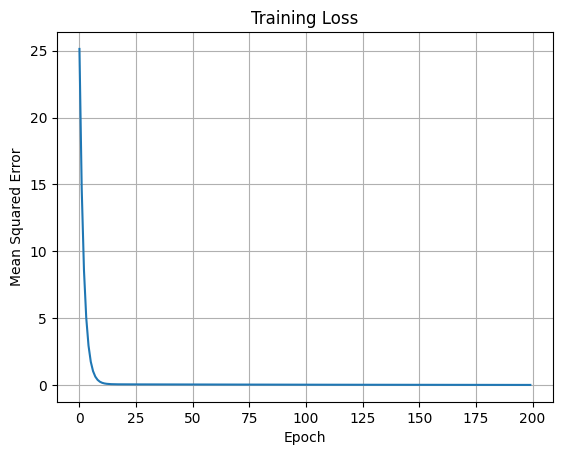

In [7]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training Loss")
plt.grid(True)
plt.show()